[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ram0ng1/Ciencia_de_Dados_Aprendizagem_Maquina/blob/main/Aprendizado_de_Maquina/notebooks/laboratorio-ramon.ipynb)

# Módulo IV — Aula 2: laboratório supervisionado (minha execução)

**Autor:** Ramon Guilherme Marques do Nascimento · Sistemas de Informação · UDF · 2026.2  
**Disciplina:** Ciência de Dados e Aprendizado de Máquina — Profa. Kadidja Valéria

Este notebook é a minha execução do roteiro da aula 2 ([notebook didático](laboratorio.ipynb)). Mantive o código-base da professora e a mesma semente (`SEMENTE = 42`), para que os números principais possam ser conferidos por qualquer pessoa. O que acrescentei:

- células de interpretação em Markdown depois de cada etapa, com o que eu observei;
- os **exercícios de investigação executados em código**: grade `max_depth` × `min_samples_leaf` (feita antes de olhar o teste), retirada de cada atributo, a pergunta dos 95%, precisão/sensibilidade/F1, pesos balanceados e limiar de decisão;
- na regressão: erros dos cinco primeiros registros, estatísticas dos resíduos, retirada de atributo por validação cruzada e um teste de extrapolação.

Todos os registros são **sintéticos**. As relações entre atributos e evasão foram escolhidas pela simulação e não dizem nada sobre estudantes reais.

Ao rodar dentro do repositório, as figuras vão para `../assets/`; no Colab, a pasta `./assets/` é criada automaticamente.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     cross_validate, cross_val_predict)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_score, recall_score, f1_score,
                             mean_absolute_error, r2_score)

SEMENTE = 42

# Pasta das figuras: ../assets quando o notebook roda dentro do repositório;
# ./assets quando roda sozinho (por exemplo, no Colab).
PASTA_ASSETS = '../assets' if os.path.isdir('../assets') else './assets'
os.makedirs(PASTA_ASSETS, exist_ok=True)

def salvar_figura(nome):
    caminho = os.path.join(PASTA_ASSETS, nome)
    plt.savefig(caminho, dpi=120, bbox_inches='tight')
    print('Figura salva em', caminho)

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__,
      '| matplotlib:', matplotlib.__version__, '| scikit-learn:', sklearn.__version__)
print('Pasta de figuras:', PASTA_ASSETS)

Python: 3.13.18
NumPy: 2.5.3 | pandas: 3.0.5 | matplotlib: 3.11.2 | scikit-learn: 1.9.1
Pasta de figuras: ../assets


**Ambiente.** As versões impressas acima são as que eu realmente usei e estão registradas no [relatório da atividade 03](../03-aula2-laboratorio.md). Diferente do notebook didático, importei também `classification_report`, `precision_score`, `recall_score`, `f1_score`, `KFold` e `cross_val_predict`, que usei nos exercícios extras.

## 1. Dados e pergunta de negócio

Pergunta: *a partir do que se sabe ao fim da semana 4, quem poderia receber um convite voluntário de apoio?* Unidade de análise: um estudante fictício em um semestre. A simulação é a mesma do roteiro; acrescentei só uma conferência de que ela reproduz o CSV distribuído na disciplina.

In [2]:
rng = np.random.default_rng(SEMENTE)
n = 600
frequencia = rng.uniform(35, 100, n)
nota = rng.uniform(0, 10, n)
entregas = rng.integers(0, 9, n)
logit = -0.4 + (65 - frequencia)/18 + (5 - nota)/2 + (4 - entregas)/3
prob_simulada = 1 / (1 + np.exp(-logit))
alvo = rng.binomial(1, prob_simulada)
dados = pd.DataFrame({'frequencia_sem4': frequencia,
                      'nota_sem4': nota, 'entregas_sem4': entregas,
                      'evasao_fim_semestre': alvo})
dados.loc[rng.choice(n, 30, replace=False), 'nota_sem4'] = np.nan

# Conferência: a simulação deve reproduzir o CSV distribuído pela professora.
csv_prof = '../dados/educacionais-sinteticos.csv'
if os.path.exists(csv_prof):
    original = pd.read_csv(csv_prof)
    iguais = np.allclose(original.fillna(-1).values, dados.fillna(-1).values)
    print('Simulação idêntica ao CSV da disciplina?', iguais)

print(dados.head().to_string(index=False))
print('Dimensões:', dados.shape)
print('Ausentes por coluna:')
print(dados.isna().sum().to_string())
print('Classes (%):')
print(dados['evasao_fim_semestre'].value_counts(normalize=True).mul(100).round(1).to_string())

Simulação idêntica ao CSV da disciplina? True
 frequencia_sem4  nota_sem4  entregas_sem4  evasao_fim_semestre
       85.307143   4.775059              0                    1
       63.527099   7.614326              5                    1
       90.808865   9.033279              6                    0
       80.328922   7.206959              4                    0
       41.121528   9.632112              3                    1
Dimensões: (600, 4)
Ausentes por coluna:
frequencia_sem4         0
nota_sem4              30
entregas_sem4           0
evasao_fim_semestre     0
Classes (%):
evasao_fim_semestre
0    59.0
1    41.0


**O que observei nos dados.**

- São 600 estudantes fictícios. A simulação gerou exatamente o mesmo conteúdo do CSV da disciplina (`True` na conferência), então o Orange e o Python trabalham sobre os mesmos registros.
- A classe 1 (evadiu) é 41,0% do total. Não é um desbalanceamento extremo, mas é suficiente para que "sempre prever permanência" acerte cerca de 59%.
- Só `nota_sem4` tem ausências: 30 valores (5%). Em um caso real, eu perguntaria **por que** a nota falta — avaliação não lançada é diferente de estudante que não fez a prova. Aqui as ausências foram sorteadas ao acaso.

## 2. Separação antes de qualquer transformação

Separo 25% para teste **antes** de calcular medianas ou olhar distribuições com mais detalhe. Tudo o que vem depois (exploração, escolha de parâmetros) usa só o treino.

Treino: 450 | Teste: 150
Proporção de evasão — treino: 0.411 | teste: 0.407
       frequencia_sem4  nota_sem4  entregas_sem4
count           450.00     427.00         450.00
mean             67.19       5.13           4.10
std              18.66       2.91           2.65
min              35.48       0.01           0.00
25%              50.54       2.55           2.00
50%              67.27       5.15           4.00
75%              83.53       7.73           7.00
max              99.94       9.99           8.00

Taxa de evasão no treino por faixa de nota:
nota_sem4
(-0.001, 2.5]    0.740
(2.5, 5.0]       0.524
(5.0, 7.5]       0.262
(7.5, 10.0]      0.111


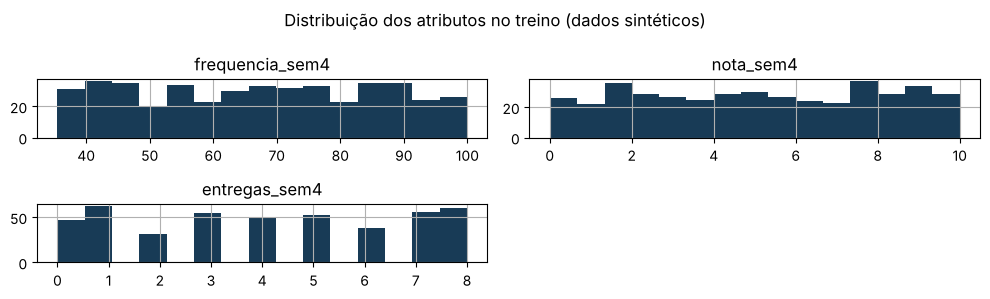

In [3]:
atributos = ['frequencia_sem4', 'nota_sem4', 'entregas_sem4']
X = dados[atributos]
y = dados['evasao_fim_semestre']
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE)
print('Treino:', len(X_treino), '| Teste:', len(X_teste))
print('Proporção de evasão — treino: %.3f | teste: %.3f' % (y_treino.mean(), y_teste.mean()))
print(X_treino.describe().round(2))
# Olhando só o treino: taxa de evasão por faixa de nota
faixas = pd.cut(X_treino['nota_sem4'], bins=[0, 2.5, 5, 7.5, 10], include_lowest=True)
print('\nTaxa de evasão no treino por faixa de nota:')
print(y_treino.groupby(faixas, observed=True).mean().round(3).to_string())
X_treino.hist(figsize=(10, 3), bins=15, color='#183b56')
plt.suptitle('Distribuição dos atributos no treino (dados sintéticos)')
plt.tight_layout(); plt.show()

**Leitura da separação.** Ficaram 450 registros para treino e 150 para teste, com proporções de evasão praticamente iguais (0,411 e 0,407), efeito do `stratify=y`.

Fiz uma exploração extra **apenas no treino**: a taxa de evasão cai de forma clara conforme a nota sobe — 74,0% na faixa de 0 a 2,5, 52,4% entre 2,5 e 5, 26,2% entre 5 e 7,5 e 11,1% acima de 7,5. Isso já antecipa que a nota deve aparecer no topo da árvore. Os histogramas mostram frequência e nota aproximadamente uniformes (como na fórmula da simulação) e entregas espalhadas entre 0 e 8.

## 3. Escolha da profundidade por validação cruzada no treino

Pipeline = imputação pela mediana + árvore. A mediana é recalculada dentro de cada dobra, então nem a validação vaza para o treino da dobra.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

def montar_arvore(profundidade, folha, pesos=None):
    return Pipeline([
        ('imputador', SimpleImputer(strategy='median')),
        ('arvore', DecisionTreeClassifier(max_depth=profundidade, min_samples_leaf=folha,
                                          class_weight=pesos, random_state=SEMENTE))])

comparacao = []
for profundidade in [2, 3, 5, None]:
    scores = cross_validate(montar_arvore(profundidade, 10), X_treino, y_treino, cv=cv,
                            scoring='accuracy', return_train_score=True)
    comparacao.append({'profundidade': str(profundidade),
                       'acuracia_treino_cv': scores['train_score'].mean(),
                       'acuracia_validacao_cv': scores['test_score'].mean(),
                       'desvio_validacao_cv': scores['test_score'].std()})
comparacao = pd.DataFrame(comparacao)
print(comparacao.round(4).to_string(index=False))
melhor = comparacao.sort_values('acuracia_validacao_cv', ascending=False, kind='stable').iloc[0]
prof = None if melhor['profundidade'] == 'None' else int(melhor['profundidade'])
print('Profundidade escolhida somente no treino:', prof)

profundidade  acuracia_treino_cv  acuracia_validacao_cv  desvio_validacao_cv
           2              0.7328                 0.6844               0.0425
           3              0.7678                 0.7022               0.0257
           5              0.8111                 0.7222               0.0391
        None              0.8206                 0.7111               0.0477
Profundidade escolhida somente no treino: 5


**Interpretação da comparação de profundidades.**

| Profundidade | Treino (média CV) | Validação (média ± desvio) | Distância |
| --- | --- | --- | --- |
| 2 | 0,7328 | 0,6844 ± 0,0425 | 0,048 |
| 3 | 0,7678 | 0,7022 ± 0,0257 | 0,066 |
| 5 | 0,8111 | **0,7222 ± 0,0391** | 0,089 |
| None | 0,8206 | 0,7111 ± 0,0477 | 0,109 |

A profundidade 5 teve a maior média de validação e foi a escolhida. Mas eu não leio isso como vitória clara: a diferença para a profundidade `None` (0,011) é bem menor que o desvio entre dobras (~0,04). O que fica nítido é a tendência: quanto mais profunda, maior a distância treino–validação. A profundidade 2 é simples demais (subajuste: erra até no treino).

## 4. Exercício 1 — tamanho mínimo das folhas (antes de olhar o teste)

O roteiro pede que essa comparação seja feita **antes** de conhecer o teste. Por isso coloquei a grade aqui, antes da avaliação final.

In [5]:
# Exercício 1 — feito ANTES de olhar o teste: grade profundidade x min_samples_leaf
grade = []
for folha in [5, 10, 20, 40]:
    for profundidade in [2, 3, 5, None]:
        s = cross_validate(montar_arvore(profundidade, folha), X_treino, y_treino, cv=cv,
                           scoring='accuracy', return_train_score=True)
        grade.append({'min_samples_leaf': folha, 'profundidade': str(profundidade),
                      'treino_cv': s['train_score'].mean(),
                      'validacao_cv': s['test_score'].mean(),
                      'desvio': s['test_score'].std(),
                      'distancia': s['train_score'].mean() - s['test_score'].mean()})
grade = pd.DataFrame(grade)
print(grade.round(4).to_string(index=False))
print('\nMelhor média de validação por tamanho de folha:')
melhores_folha = grade.loc[grade.groupby('min_samples_leaf')['validacao_cv'].idxmax()]
print(melhores_folha.round(4).to_string(index=False))

 min_samples_leaf profundidade  treino_cv  validacao_cv  desvio  distancia
                5            2     0.7328        0.6844  0.0425     0.0483
                5            3     0.7706        0.7000  0.0233     0.0706
                5            5     0.8261        0.7222  0.0298     0.1039
                5         None     0.8678        0.7133  0.0215     0.1544
               10            2     0.7328        0.6844  0.0425     0.0483
               10            3     0.7678        0.7022  0.0257     0.0656
               10            5     0.8111        0.7222  0.0391     0.0889
               10         None     0.8206        0.7111  0.0477     0.1094
               20            2     0.7328        0.6844  0.0425     0.0483
               20            3     0.7656        0.6978  0.0325     0.0678
               20            5     0.7900        0.7267  0.0480     0.0633
               20         None     0.7900        0.7267  0.0480     0.0633
               40        

**Interpretação e decisão.**

| `min_samples_leaf` | Melhor profundidade | Treino CV | Validação CV ± desvio | Distância treino–validação |
| --- | --- | --- | --- | --- |
| 5 | 5 | 0,8261 | 0,7222 ± 0,0298 | 0,104 |
| 10 (roteiro) | 5 | 0,8111 | 0,7222 ± 0,0391 | 0,089 |
| 20 | 5 (= None) | 0,7900 | 0,7267 ± 0,0480 | 0,063 |
| 40 | 5 (= None) | 0,7756 | 0,7289 ± 0,0303 | 0,047 |

1. **Folhas maiores encurtam a distância entre treino e validação** (de 0,154 com folha 5 e profundidade `None` para 0,047 com folha 40). Com folha 20 ou 40, profundidade 5 e `None` dão o mesmo resultado: a árvore já para de crescer por falta de registros nas folhas, antes de chegar ao limite de profundidade.
2. A maior média de validação foi a da folha 40 (0,7289), mas ela está só **0,0067 acima** da configuração do roteiro, e o desvio entre dobras é de 0,03 a 0,05. Com 450 registros, essa diferença está dentro do que o acaso da divisão em dobras produz.
3. **Minha decisão (registrada antes do teste):** manter `max_depth=5`, `min_samples_leaf=10`. Não há ganho de validação que justifique trocar, e manter a configuração do roteiro permite comparar meu resultado com o da turma. Se eu quisesse privilegiar estabilidade, a folha 40 seria uma escolha defensável, porque ela tem a menor distância treino–validação; anotei isso como hipótese para uma próxima rodada com um teste novo.

## 5. Avaliação final no teste (uma única vez)

Acurácia treino: 0.8133
Acurácia teste: 0.7800; referência: 0.5933
Matriz [linhas reais, colunas previstas]:
 [[75 14]
 [19 42]]
TN: 75 FP: 14 FN: 19 TP: 42
Acurácia pela matriz: (75 + 42) / 150 = 0.7800
Sensibilidade classe 1: 42 / 61 = 0.6885


Figura salva em ../assets/matriz-confusao.png


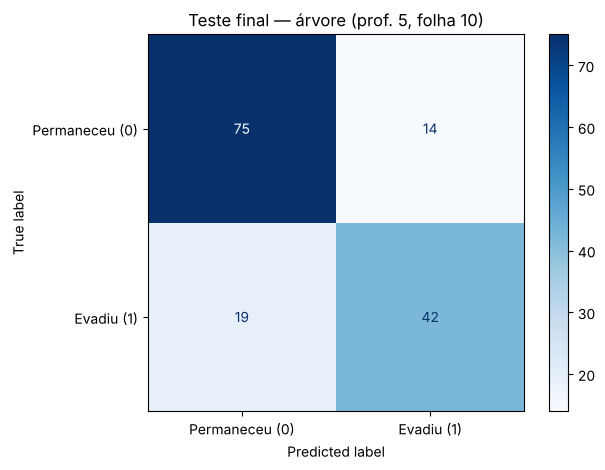

Figura salva em ../assets/arvore.png


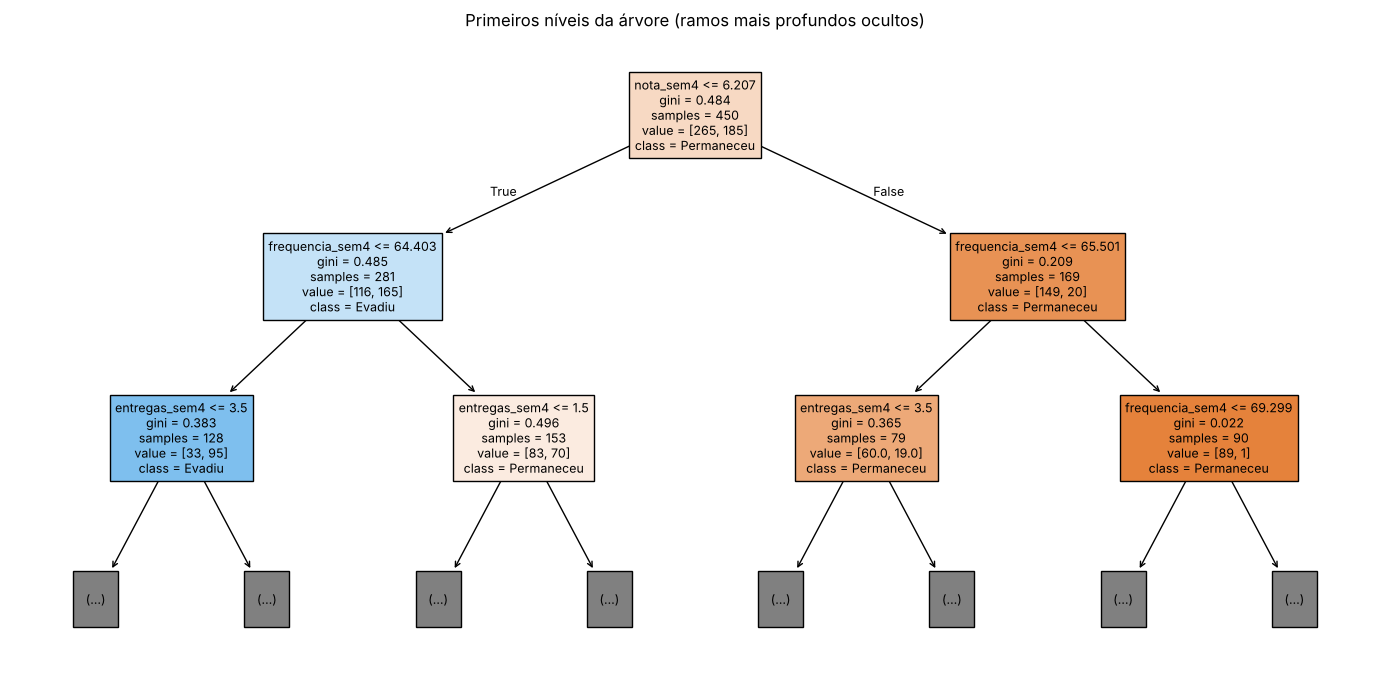

Importância dos atributos na árvore:
nota_sem4          0.622
frequencia_sem4    0.235
entregas_sem4      0.143


In [6]:
modelo = montar_arvore(prof, 10)
modelo.fit(X_treino, y_treino)
prev = modelo.predict(X_teste)
base = DummyClassifier(strategy='most_frequent').fit(X_treino, y_treino)
acc = accuracy_score(y_teste, prev)
acc_base = accuracy_score(y_teste, base.predict(X_teste))
cm = confusion_matrix(y_teste, prev, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
acc_treino = modelo.score(X_treino, y_treino)
print(f'Acurácia treino: {acc_treino:.4f}')
print(f'Acurácia teste: {acc:.4f}; referência: {acc_base:.4f}')
print('Matriz [linhas reais, colunas previstas]:\n', cm)
print('TN:', tn, 'FP:', fp, 'FN:', fn, 'TP:', tp)
print('Acurácia pela matriz: (%d + %d) / %d = %.4f' % (tn, tp, cm.sum(), (tn + tp) / cm.sum()))
print('Sensibilidade classe 1: %d / %d = %.4f' % (tp, tp + fn, tp / (tp + fn)))

ConfusionMatrixDisplay(cm, display_labels=['Permaneceu (0)', 'Evadiu (1)']).plot(cmap='Blues')
plt.title('Teste final — árvore (prof. %s, folha 10)' % prof)
plt.tight_layout(); salvar_figura('matriz-confusao.png'); plt.show()

plt.figure(figsize=(14, 7))
plot_tree(modelo.named_steps['arvore'], feature_names=atributos,
          class_names=['Permaneceu', 'Evadiu'], max_depth=2, filled=True, fontsize=9)
plt.title('Primeiros níveis da árvore (ramos mais profundos ocultos)')
plt.tight_layout(); salvar_figura('arvore.png'); plt.show()

importancias = pd.Series(modelo.named_steps['arvore'].feature_importances_, index=atributos)
print('Importância dos atributos na árvore:')
print(importancias.round(3).sort_values(ascending=False).to_string())

**Leitura do teste final.**

- Acurácia no teste: **0,7800**, contra **0,5933** da referência que sempre prevê "permaneceu". São 18,7 pontos percentuais acima da referência.
- Conferência manual pela matriz: (TN + TP) / total = (75 + 42) / 150 = 117 / 150 = **0,78**. Bate com o `accuracy_score`.
- Sensibilidade da classe 1: TP / (TP + FN) = 42 / 61 = **0,689**. De cada 10 estudantes fictícios que evadiram, a árvore sinaliza cerca de 7.
- A acurácia de treino (0,8133) é maior que a do teste (0,78), e a média de validação (0,7222) ficou **abaixo** do teste. Com só 150 registros no teste, um ponto percentual equivale a 1,5 estudante; essa variação é esperada e não significa que o modelo "melhorou" no teste.

**Erros.** Os 14 falsos positivos seriam estudantes contatados sem necessidade (custo: tempo da equipe e possível incômodo). Os 19 falsos negativos são quem evadiu e não foi sinalizado — para mim, o erro mais sério, porque a pessoa fica sem convite. Por isso a sinalização não pode ser a única porta de entrada para o apoio.

**Árvore.** A primeira pergunta é `nota_sem4 ≤ 6,21`. Nos dois ramos, a segunda pergunta é sobre frequência (≤ 64,40 à esquerda e ≤ 65,50 à direita), e as entregas aparecem no terceiro nível. Um detalhe que chamou minha atenção: no ramo nota > 6,21 e frequência > 69,30, os 79 estudantes de treino que caíram ali permaneceram (folha pura). As importâncias ficaram em nota 0,622, frequência 0,235 e entregas 0,143. Isso descreve **como esta árvore separa estes dados sintéticos**, e não por que alguém evade.

In [7]:
# Extra: métricas por classe no teste (mesmo modelo, sem nova escolha)
print(classification_report(y_teste, prev, target_names=['Permaneceu (0)', 'Evadiu (1)'], digits=3))
precisao_1 = precision_score(y_teste, prev)
f1_1 = f1_score(y_teste, prev)
print('Precisão classe 1: %.4f | F1 classe 1: %.4f' % (precisao_1, f1_1))

                precision    recall  f1-score   support

Permaneceu (0)      0.798     0.843     0.820        89
    Evadiu (1)      0.750     0.689     0.718        61

      accuracy                          0.780       150
     macro avg      0.774     0.766     0.769       150
  weighted avg      0.778     0.780     0.778       150

Precisão classe 1: 0.7500 | F1 classe 1: 0.7179


**Precisão, sensibilidade e F1 (extra).** O relatório por classe mostra o que a acurácia esconde: para a classe 1, a precisão é 0,750 (de cada 4 sinalizados, 3 de fato evadiram) e a sensibilidade é 0,689; o F1 da classe 1 é 0,718, menor que o da classe 0 (0,820). O modelo é melhor em reconhecer quem permanece do que em encontrar quem evade. Isso importa, porque a decisão de apoio depende justamente da classe 1.

## 6. Extra — pesos balanceados e limiar de decisão (só no treino)

A árvore decide "evadiu" quando a estimativa da folha é ≥ 0,5. Se a equipe de apoio prefere errar por excesso de convite, dá para baixar esse limiar. Para não contaminar o teste, avaliei isso com `cross_val_predict` no treino: cada registro recebe a estimativa de um modelo que não o viu.

In [8]:
# Extra: pesos balanceados e limiar de decisão — avaliados SOMENTE por validação cruzada no treino
linhas = []
for pesos in [None, 'balanced']:
    proba_cv = cross_val_predict(montar_arvore(prof, 10, pesos), X_treino, y_treino,
                                 cv=cv, method='predict_proba')[:, 1]
    for limiar in [0.3, 0.4, 0.5]:
        pred_cv = (proba_cv >= limiar).astype(int)
        linhas.append({'class_weight': str(pesos), 'limiar': limiar,
                       'acuracia': accuracy_score(y_treino, pred_cv),
                       'precisao_1': precision_score(y_treino, pred_cv),
                       'sensibilidade_1': recall_score(y_treino, pred_cv),
                       'f1_1': f1_score(y_treino, pred_cv),
                       'sinalizados': int(pred_cv.sum())})
experimento_limiar = pd.DataFrame(linhas)
print('Validação cruzada (previsões fora da dobra, 450 registros de treino; %d evasões reais)' % y_treino.sum())
print(experimento_limiar.round(4).to_string(index=False))

Validação cruzada (previsões fora da dobra, 450 registros de treino; 185 evasões reais)
class_weight  limiar  acuracia  precisao_1  sensibilidade_1   f1_1  sinalizados
        None     0.3    0.6889      0.5896           0.8000 0.6789          251
        None     0.4    0.7156      0.6338           0.7297 0.6784          213
        None     0.5    0.7222      0.6579           0.6757 0.6667          190
    balanced     0.3    0.6822      0.5761           0.8595 0.6898          276
    balanced     0.4    0.6978      0.6052           0.7622 0.6746          233
    balanced     0.5    0.7244      0.6517           0.7081 0.6788          201


**O que o experimento mostra (validação no treino, 185 evasões reais em 450):**

| Configuração | Sensibilidade classe 1 | Precisão classe 1 | Estudantes sinalizados |
| --- | --- | --- | --- |
| Sem pesos, limiar 0,5 (padrão) | 0,676 | 0,658 | 190 |
| Sem pesos, limiar 0,4 | 0,730 | 0,634 | 213 |
| Sem pesos, limiar 0,3 | 0,800 | 0,590 | 251 |
| `class_weight='balanced'`, limiar 0,5 | 0,708 | 0,652 | 201 |
| `class_weight='balanced'`, limiar 0,3 | 0,860 | 0,576 | 276 |

Baixar o limiar troca precisão por sensibilidade: com 0,3 encontro 80% das evasões, mas sinalizo 251 de 450 estudantes — mais da metade da turma, o que provavelmente passa da capacidade da equipe. Os pesos balanceados deram um ganho pequeno de sensibilidade no limiar 0,5 (0,676 → 0,708) quase sem perder precisão. **Não apliquei nenhuma dessas variações ao teste**: o teste já foi usado, e escolher limiar por ele tornaria a estimativa otimista. Para adotar, por exemplo, limiar 0,4, eu precisaria de um conjunto de teste novo. A escolha do limiar é, no fundo, uma decisão de **capacidade de atendimento**, não só uma decisão técnica.

## 7. Previsão de novos registros fictícios

In [9]:
novos = pd.DataFrame({'frequencia_sem4': [72.0, 50.0, 90.0],
                      'nota_sem4': [6.0, 4.0, np.nan],
                      'entregas_sem4': [5, 2, 7]})
indice_1 = list(modelo.named_steps['arvore'].classes_).index(1)
novos['classe_prevista'] = modelo.predict(novos[atributos])
novos['estimativa_classe_1'] = modelo.predict_proba(novos[atributos])[:, indice_1].round(3)
print(novos.to_string(index=False))

 frequencia_sem4  nota_sem4  entregas_sem4  classe_prevista  estimativa_classe_1
            72.0        6.0              5                0                0.342
            50.0        4.0              2                1                0.968
            90.0        NaN              7                0                0.171


**Leitura.** O caso do roteiro (frequência 72, nota 6, 5 entregas) recebe estimativa 0,342 para a classe 1, ou seja, "permaneceu". Um estudante com frequência 50, nota 4 e 2 entregas cai em uma folha com 0,968. O terceiro caso não tem nota: o pipeline imputa a mediana aprendida no treino, sem que eu precise tratar isso à mão. Essas estimativas são proporções de estudantes de treino nas folhas, e não probabilidades calibradas. Servem para ordenar quem contatar primeiro.

## 8. Exercício 4 — retirar um atributo de cada vez

In [10]:
# Exercício 4 — remover um atributo de cada vez (validação cruzada no treino)
remocao = []
for retirado in [None] + atributos:
    cols = [a for a in atributos if a != retirado]
    s = cross_validate(montar_arvore(prof, 10), X_treino[cols], y_treino, cv=cv, scoring='accuracy')
    remocao.append({'atributo_retirado': retirado or '(nenhum)',
                    'validacao_cv': s['test_score'].mean(), 'desvio': s['test_score'].std()})
remocao = pd.DataFrame(remocao)
remocao['queda_vs_completo'] = remocao['validacao_cv'].iloc[0] - remocao['validacao_cv']
print(remocao.round(4).to_string(index=False))

atributo_retirado  validacao_cv  desvio  queda_vs_completo
         (nenhum)        0.7222  0.0391             0.0000
  frequencia_sem4        0.7156  0.0362             0.0067
        nota_sem4        0.6289  0.0475             0.0933
    entregas_sem4        0.7022  0.0310             0.0200


**Interpretação.** Com os três atributos, a validação média é 0,7222. Sem frequência: 0,7156 (−0,007); sem entregas: 0,7022 (−0,020); sem nota: 0,6289 (**−0,093**). Só a retirada da nota provoca uma queda maior que o desvio entre dobras. Isso mostra que a nota carrega a maior parte da informação **útil para prever** nesta simulação. Não prova que a nota *causa* evasão: a mudança de acurácia mede utilidade preditiva dentro deste conjunto, e atributos correlacionados podem cobrir uns aos outros. Em dados reais, uma causa comum (trabalho, saúde, renda) poderia derrubar nota e frequência ao mesmo tempo.

## 9. Exercício 5 — e se 95% permanecessem?

In [11]:
# Exercício 5 — e se 95% permanecessem? Turma hipotética de 200 estudantes, 10 evasões.
y_hipotetico = np.array([0] * 190 + [1] * 10)
sempre_permanece = np.zeros_like(y_hipotetico)
cm_hip = confusion_matrix(y_hipotetico, sempre_permanece, labels=[0, 1])
print('Acurácia de sempre prever permanência:', accuracy_score(y_hipotetico, sempre_permanece))
print('Matriz:\n', cm_hip)
print('Sensibilidade classe 1:', recall_score(y_hipotetico, sempre_permanece, zero_division=0))

Acurácia de sempre prever permanência: 0.95
Matriz:
 [[190   0]
 [ 10   0]]
Sensibilidade classe 1: 0.0


**Resposta.** Em uma turma hipotética de 200 estudantes com 10 evasões, "sempre prever permanência" acerta **0,95**, mas a matriz mostra TP = 0 e FN = 10: sensibilidade **zero**. É um modelo que parece excelente pela acurácia e é inútil para o objetivo, que é encontrar quem precisa de apoio. Por isso eu comparo sempre com a referência e olho a matriz e a sensibilidade.

# Seção independente: regressão linear

## 10. Demanda semanal de empréstimos de uma biblioteca

Alvo numérico: empréstimos por semana. Atributos: usuários ativos e horas de abertura. Mantive a simulação e a divisão do roteiro.

Treino: 225 | Teste: 75
MAE teste: 28.59 empréstimos/semana | R² teste: 0.8774
Referência (média do treino): MAE 84.73 | R² -0.0037
Coeficientes: {'usuarios_ativos': 0.348, 'horas_abertura': 2.297} | intercepto: 37.32


Figura salva em ../assets/regressao-observado-previsto.png


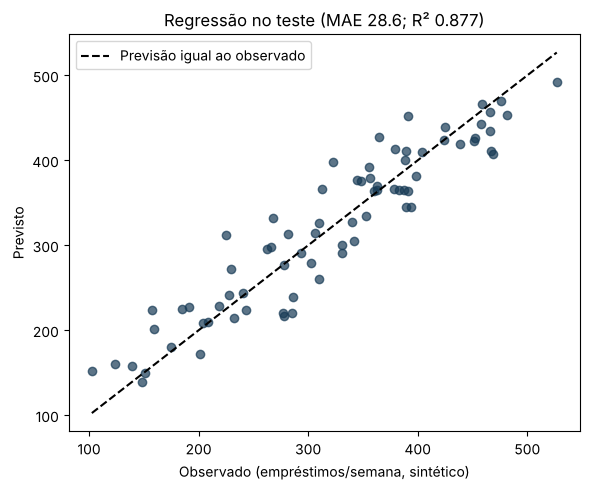

Figura salva em ../assets/regressao-residuos.png


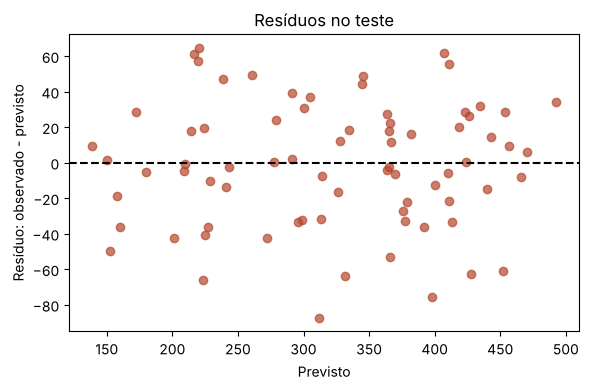

In [12]:
rng_reg = np.random.default_rng(SEMENTE)
reg = pd.DataFrame({'usuarios_ativos': rng_reg.uniform(100, 1000, 300),
                    'horas_abertura': rng_reg.uniform(20, 60, 300)})
reg['emprestimos_semana'] = (30 + 0.35*reg['usuarios_ativos'] +
                             2.5*reg['horas_abertura'] + rng_reg.normal(0, 35, 300))
atr_reg = ['usuarios_ativos', 'horas_abertura']
Xr = reg[atr_reg]
yr = reg['emprestimos_semana']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.25, random_state=SEMENTE)
regressor = Pipeline([('imputador', SimpleImputer(strategy='median')),
                      ('linear', LinearRegression())])
regressor.fit(Xr_tr, yr_tr)
pr = regressor.predict(Xr_te)
ref_reg = DummyRegressor(strategy='mean').fit(Xr_tr, yr_tr)
mae = mean_absolute_error(yr_te, pr)
r2 = r2_score(yr_te, pr)
mae_base = mean_absolute_error(yr_te, ref_reg.predict(Xr_te))
r2_base = r2_score(yr_te, ref_reg.predict(Xr_te))
lin = regressor.named_steps['linear']
print('Treino:', len(Xr_tr), '| Teste:', len(Xr_te))
print(f'MAE teste: {mae:.2f} empréstimos/semana | R² teste: {r2:.4f}')
print(f'Referência (média do treino): MAE {mae_base:.2f} | R² {r2_base:.4f}')
print('Coeficientes:', {a: round(float(c), 4) for a, c in zip(atr_reg, lin.coef_)}, '| intercepto: %.2f' % lin.intercept_)

plt.figure(figsize=(6, 5)); plt.scatter(yr_te, pr, alpha=0.7, color='#183b56')
lim = [min(yr_te.min(), pr.min()), max(yr_te.max(), pr.max())]
plt.plot(lim, lim, 'k--', label='Previsão igual ao observado')
plt.xlabel('Observado (empréstimos/semana, sintético)'); plt.ylabel('Previsto')
plt.title('Regressão no teste (MAE %.1f; R² %.3f)' % (mae, r2)); plt.legend()
plt.tight_layout(); salvar_figura('regressao-observado-previsto.png'); plt.show()

residuos = yr_te - pr
plt.figure(figsize=(6, 4)); plt.scatter(pr, residuos, alpha=0.7, color='#b5462e')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Previsto'); plt.ylabel('Resíduo: observado - previsto')
plt.title('Resíduos no teste'); plt.tight_layout(); salvar_figura('regressao-residuos.png'); plt.show()

**Leitura da regressão.**

- **MAE = 28,59 empréstimos por semana** no teste, contra **84,73** da referência que sempre prevê a média do treino. O erro médio caiu para cerca de um terço.
- **R² = 0,8774.** A referência teve R² de −0,0037 no teste: quase zero, como esperado, e levemente negativo porque usa a média do *treino*, não a do teste.
- Coeficientes: 0,348 empréstimo por usuário ativo e 2,297 por hora de abertura (intercepto 37,32). A simulação usou 0,35 e 2,5; o modelo recuperou valores próximos, o que só é possível porque eu *sei* a fórmula que gerou os dados. Em dados reais, isso seria associação, não efeito causal das horas sobre empréstimos.
- **Gráfico observado × previsto:** os pontos acompanham a diagonal ao longo de toda a faixa, sem curvatura. **Resíduos:** espalhados em torno de zero, sem formato de funil nem de curva.

In [13]:
# Exercícios da regressão
# (a) erros absolutos dos cinco primeiros registros do teste
primeiros = pd.DataFrame({'real': yr_te, 'previsto': pr, 'erro_absoluto': np.abs(yr_te - pr)}).head()
print(primeiros.round(2))
print('Média dos 5 erros: %.2f' % primeiros['erro_absoluto'].mean())

# (b) estatísticas dos resíduos
print('\nResíduos — média %.2f | desvio %.2f | mín %.2f | máx %.2f | |resíduo| > 50: %d de %d'
      % (residuos.mean(), residuos.std(), residuos.min(), residuos.max(),
         (residuos.abs() > 50).sum(), len(residuos)))
print('Correlação resíduo x previsto: %.3f' % np.corrcoef(pr, residuos)[0, 1])

# (c) retirar um atributo — validação cruzada em 5 partes só no treino
kf = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
linhas_reg = []
for cols in [atr_reg, ['usuarios_ativos'], ['horas_abertura']]:
    s = cross_validate(Pipeline([('imputador', SimpleImputer(strategy='median')),
                                 ('linear', LinearRegression())]),
                       Xr_tr[cols], yr_tr, cv=kf, scoring=['neg_mean_absolute_error', 'r2'])
    linhas_reg.append({'atributos': ' + '.join(cols),
                       'MAE_cv': -s['test_neg_mean_absolute_error'].mean(),
                       'desvio_MAE': s['test_neg_mean_absolute_error'].std(),
                       'R2_cv': s['test_r2'].mean()})
print()
print(pd.DataFrame(linhas_reg).round(3).to_string(index=False))

# (d) extrapolação: o modelo responde, mas fora do domínio observado (100–1000 usuários; 20–60 h)
fora = pd.DataFrame({'usuarios_ativos': [500, 10000], 'horas_abertura': [40, 100]})
print('\nPrevisões (dentro e fora do domínio):', regressor.predict(fora).round(1))

       real  previsto  erro_absoluto
203  208.90    209.40           0.50
266  277.71    277.32           0.39
152  190.95    227.18          36.23
9    229.67    271.95          42.29
233  359.77    363.62           3.85
Média dos 5 erros: 16.65

Resíduos — média -1.28 | desvio 35.47 | mín -87.24 | máx 64.59 | |resíduo| > 50: 12 de 75
Correlação resíduo x previsto: 0.027



                       atributos  MAE_cv  desvio_MAE  R2_cv
usuarios_ativos + horas_abertura  28.892       1.771  0.867
                 usuarios_ativos  35.904       3.192  0.798
                  horas_abertura  83.728       5.357  0.048

Previsões (dentro e fora do domínio): [ 303.2 3746.9]


**Exercícios da regressão — o que encontrei.**

1. **Cinco primeiros erros absolutos:** 0,50; 0,39; 36,23; 42,29 e 3,85 (média 16,65). Nesse recorte, dois registros quase exatos convivem com dois erros acima de 36 empréstimos. Isso ilustra que o MAE de 28,59 é uma média: algumas semanas erram muito mais.
2. **Resíduos:** média −1,28 (praticamente sem viés), desvio 35,47 (próximo do ruído σ = 35 da simulação), mínimo −87,24 e máximo 64,59. Em 12 das 75 semanas de teste o erro passou de 50 empréstimos. A correlação entre resíduo e valor previsto é 0,027, sem tendência sistemática.
3. **Retirada de atributo (validação cruzada em 5 partes, só no treino):** com os dois atributos, MAE 28,89 e R² 0,867. Só com usuários ativos, MAE 35,90 e R² 0,798. Só com horas de abertura, MAE 83,73 e R² 0,048, praticamente igual a prever a média. Usuários ativos explicam a maior parte da variação; as horas acrescentam uma melhora real, mas menor. De novo, isso mede utilidade para prever, e não causa.
4. **Extrapolação:** para 500 usuários e 40 horas (dentro do domínio), a previsão é 303,2. Para 10.000 usuários e 100 horas, o modelo responde 3.746,9 sem hesitar. Esse número não tem respaldo: nenhum registro de treino passou de 1.000 usuários ou 60 horas, e nada garante que a relação continue linear (acervo e equipe têm limite).

**Por que R² não é porcentagem de acertos:** R² compara o erro quadrático do modelo com o erro de prever sempre a média. Em regressão, praticamente nenhuma previsão é exatamente igual ao valor real; 0,877 quer dizer "erro quadrático cerca de 88% menor que o da média", e não que 88% das semanas foram acertadas.

## 11. Registro dos resultados

In [14]:
resultados = {
    'autor': 'Ramon Guilherme Marques do Nascimento',
    'acuracia_treino': float(acc_treino), 'acuracia_teste': float(acc),
    'acuracia_referencia': float(acc_base), 'matriz_confusao': cm.tolist(),
    'sensibilidade_classe1': float(tp / (tp + fn)), 'precisao_classe1': float(precisao_1),
    'f1_classe1': float(f1_1), 'profundidade': prof, 'min_samples_leaf': 10,
    'validacao_escolhida': float(melhor['acuracia_validacao_cv']),
    'desvio_validacao_escolhida': float(melhor['desvio_validacao_cv']),
    'grade_folhas': grade.round(4).to_dict(orient='records'),
    'remocao_atributos': remocao.round(4).to_dict(orient='records'),
    'experimento_limiar': experimento_limiar.round(4).to_dict(orient='records'),
    'mae': float(mae), 'r2': float(r2), 'mae_referencia': float(mae_base),
    'coeficientes_regressao': [float(c) for c in lin.coef_], 'intercepto': float(lin.intercept_),
    'residuos': {'media': float(residuos.mean()), 'desvio': float(residuos.std()),
                 'min': float(residuos.min()), 'max': float(residuos.max())},
    'python': sys.version.split()[0], 'sklearn': sklearn.__version__, 'pandas': pd.__version__,
    'numpy': np.__version__, 'matplotlib': matplotlib.__version__}
with open('resultados_execucao.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)
print('resultados_execucao.json gravado.')

resultados_execucao.json gravado.


## Conclusões desta execução

- A árvore (profundidade 5, folha 10) ficou com acurácia de teste **0,78** e sensibilidade **0,689**, bem acima da referência (0,593 e sensibilidade 0). A nota da semana 4 é o atributo mais útil para prever nesta simulação.
- Escolhi tudo por validação cruzada no treino. O teste foi usado uma vez. Os experimentos extras (folhas, pesos, limiar, retirada de atributos) ficaram restritos ao treino.
- A regressão teve MAE de 28,59 empréstimos/semana e R² de 0,877; serve para planejamento dentro da faixa observada, não para extrapolar.
- **Limites:** os dados são sintéticos e as associações foram definidas pela simulação; existe só uma divisão de teste; não há grupos reais para auditar equidade. Qualquer uso real exigiria divisão temporal, revisão ética, minimização de dados e decisão humana sobre o contato com cada estudante.

## Referências

- SCIKIT-LEARN. *User Guide* (Decision Trees; Cross-validation; Model evaluation). Disponível em: https://scikit-learn.org/stable/user_guide.html. Acesso em: 16 out. 2026.
- SCIKIT-LEARN. *Common pitfalls and recommended practices*. Disponível em: https://scikit-learn.org/stable/common_pitfalls.html. Acesso em: 16 out. 2026.
- PANDAS. *User Guide*. Disponível em: https://pandas.pydata.org/docs/user_guide/index.html. Acesso em: 16 out. 2026.
- Notebook didático da Profa. Kadidja Valéria (Módulo IV, UDF, 2026), base do código desta execução.

### Checklist

- [x] Executei todas as células e registrei versões.
- [x] Identifiquei atributos, alvo e janela temporal.
- [x] Escolhi parâmetros apenas com o treino.
- [x] Interpretei matriz, acurácia, MAE e R².
- [x] Comparei referências e expliquei limitações.
- [x] Propus apoio humano e proteção dos dados (ver [atividade 04](../04-pbl-permanencia.md)).